# Evaluacion de RAG usando otros modelos de embedding

El RAG que hemos generado fue usando un modelo free de gemini. A pesar de que obtuvimos resultados satisfactorios podemos hacernos la pregunta de como cambiaria el resultado si usamos un modelo distinto.

Para responder a esta pregunta se propone usar distintos modelos free que povee cloudfare, y eso es lo que haremos en este notebook.

Antes de esto nos es conveniente  copiar dentro de una carpeta el FAISS que hemos generado con el modelo anterior 

<div align="center">
  <img src="./img/02_evaluacion_rag/image copy 19.png" width="200" alt="Prueba de agentes conectados en consola" />
</div>

## Procedimiento para pruebas

Para probar estos modelos lo que vamos a hacer es lo siguiente:

* Ir al `.env`, y cambiar al modelo elegido (tenemos que haber registrado nuestra cuenta de cloudfare y la api key previamente)
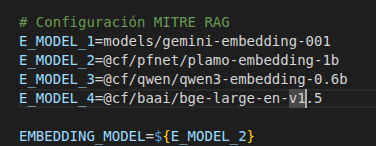

* Ejecutar el comando `uv run python -m capazeta.rag.build --force --no-download`: Lo que va a ser esto es utilizar las tecnicas que ya tenemos instalados en lugar de instalarlas nuevamente y en base a eso va a sobreescribir el RAG previamente construido, por eso se recomienda copiar el RAG con el modelo de gemini para no tener que construirlo nuevamente

## Funciones de evaluacion

Se utilizara la version utilizada en el notebook anterior

In [1]:
from langsmith.evaluation import evaluate
def mitre_retrieval_evaluator(run, example) -> list[dict]:
    """
    Evaluador robusto a prueba de errores de parseo o tipos de datos en LangSmith.
    """
    try:
        # 1. Extraer la técnica esperada de forma segura
        ref_out = example.outputs.get("mitre_id") or example.outputs.get("reference.mitre_id")
        if isinstance(ref_out, dict):
            tecnica_esperada = str(ref_out.get("mitre_id", "")).strip()
        else:
            tecnica_esperada = str(ref_out).strip()
            
        # 2. Extraer las técnicas recuperadas por la corrida
        outputs = run.outputs or {}
        tecnicas_recuperadas = outputs.get("tecnicas_recuperadas", [])
        
        # Sanitizar lista a strings simples
        tecnicas_recuperadas = [str(t).strip() for t in tecnicas_recuperadas]
        
        # 3. Calcular Hit@5
        hit = 1.0 if tecnica_esperada in tecnicas_recuperadas else 0.0
        
        # 4. Calcular MRR
        if tecnica_esperada in tecnicas_recuperadas:
            rank = tecnicas_recuperadas.index(tecnica_esperada) + 1
            mrr = 1.0 / rank
        else:
            mrr = 0.0

        return [
            {"key": "hit@5", "score": hit},
            {"key": "mrr", "score": mrr}
        ]

    except Exception as e:
        # Si ocurre cualquier falla inesperada, devuelve 0.0 en lugar de dejar la fila vacía (No feedback)
        return [
            {"key": "hit@5", "score": 0.0},
            {"key": "mrr", "score": 0.0}
        ]
    
# 2. Ejecutar la Evaluación en LangSmith
dataset_name = "Evaluacion_Wazuh_MITRE"


In [2]:
import os
import sys
from pathlib import Path

# El kernel corre en notebooks/: el índice FAISS vive en la raíz del repo.
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.environ["MITRE_DATA_DIR"] = str(root / "data" / "mitre")

# Si el kernel ya importó capazeta con otra ruta o con otro modelo de embeddings,
# forzamos reimportar (config, embeddings y rag) para no mezclar dimensiones.
for _mod in [
    m
    for m in sys.modules
    if m in {"capazeta.config", "capazeta.embeddings"} or m.startswith("capazeta.rag")
]:
    del sys.modules[_mod]

from capazeta.rag import search


In [3]:
import json
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Cargaoms la base de conocimiento de MITRE desde el JSON
json_path = "../data/mitre/techniques_vigentes.json" 

with open(json_path, 'r', encoding='utf-8') as f:
    mitre_data = json.load(f)

ids_mitre = []
textos_mitre = []

# Procesamiento exacto para  estructura de JSON
for t_id, info in mitre_data.items():
    ids_mitre.append(t_id)
    nombre = info.get("name", "")
    descripcion = info.get("description", "")
    textos_mitre.append(f"{nombre} {descripcion}")

print(f"Se cargaron {len(ids_mitre)} técnicas de MITRE exitosamente.")
# 2. Inicializamos y ajustamos el modelo TF-IDF (El motor de palabras clave)
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(textos_mitre)

# 3. Definimos el pipeline del Baseline para LangSmith
def keyword_baseline_pipeline(inputs: dict) -> dict:
    """
    Busca las 5 técnicas de MITRE más similares a la alerta usando coincidencia exacta de palabras (TF-IDF).
    """
    alerta_texto = inputs["rule.description"]
    
    # Vectorizamos la alerta entrante
    alerta_vec = vectorizer.transform([alerta_texto])
    
    # Calculamos la similitud contra todas las técnicas de MITRE
    similitudes = cosine_similarity(alerta_vec, tfidf_matrix).flatten()
    
    # Obtenemos los índices de los 5 resultados con mayor puntuación
    top_5_indices = similitudes.argsort()[-5:][::-1]
    
    # Extraemos los IDs correspondientes
    tecnicas_recuperadas = [ids_mitre[i] for i in top_5_indices]
    
    return {"tecnicas_recuperadas": tecnicas_recuperadas}

# Prueba rápida manual antes de ejecutar LangSmith:
ejemplo_alerta = {"rule.description": "Successful sudo to ROOT executed"}
print("Predicción Baseline:", keyword_baseline_pipeline(ejemplo_alerta))

Se cargaron 706 técnicas de MITRE exitosamente.
Predicción Baseline: {'tecnicas_recuperadas': ['T1548.003', 'T1553.004', 'T1098.007', 'T1078.001', 'T1548.004']}


## Evaluacion del modelo

In [ ]:
from capazeta.config import EMBEDDING_MODEL

slug = EMBEDDING_MODEL.split("/")[-1]


def rag_capazeta_pipeline(inputs: dict) -> dict:
    """Consulta el índice FAISS de Capazeta y devuelve el Top 5 de técnicas."""
    alerta_texto = inputs["rule.description"]
    resultados = search(alerta_texto, k=5)
    return {"tecnicas_recuperadas": [r["id"] for r in resultados if r.get("id")]}


results_rag = evaluate(
    rag_capazeta_pipeline,
    data=dataset_name,
    evaluators=[mitre_retrieval_evaluator],
    experiment_prefix=f"Capazeta_RAG_FAISS_{slug}",
)

df_rag = results_rag.to_pandas()
df_rag.to_csv(f"../reports/evaluacion_capazeta_rag_{slug}.csv", index=False)
print(f"¡Evaluación finalizada con {EMBEDDING_MODEL}! Revisa tu panel de LangSmith.")


<div align="center">
  <img src="./img/03_evaluacion_modelo_embedding/image copy 2.png" width="1200" alt="Prueba de agentes conectados en consola" />
</div>

Las filas en las que aparece no feedback significa que el modelo no pudo identificar correctamente ninguna regla.

Luego al final compararemos todos los resultados

## Modelo 2: qwen3-embedding-0.6b

### Construccion del embedding

<div align="center">
  <img src="./img/03_evaluacion_modelo_embedding/image copy.png" width="1200" alt="Prueba de agentes conectados en consola" />
</div>

In [ ]:
from capazeta.config import EMBEDDING_MODEL

slug = EMBEDDING_MODEL.split("/")[-1]


def rag_capazeta_pipeline(inputs: dict) -> dict:
    """Consulta el índice FAISS de Capazeta y devuelve el Top 5 de técnicas."""
    alerta_texto = inputs["rule.description"]
    resultados = search(alerta_texto, k=5)
    return {"tecnicas_recuperadas": [r["id"] for r in resultados if r.get("id")]}


results_rag = evaluate(
    rag_capazeta_pipeline,
    data=dataset_name,
    evaluators=[mitre_retrieval_evaluator],
    experiment_prefix=f"Capazeta_RAG_FAISS_{slug}",
)

df_rag = results_rag.to_pandas()
df_rag.to_csv(f"../reports/evaluacion_capazeta_rag_{slug}.csv", index=False)
print(f"¡Evaluación finalizada con {EMBEDDING_MODEL}! Revisa tu panel de LangSmith.")


<div align="center">
  <img src="./img/03_evaluacion_modelo_embedding/image copy 3.png" width="1200" alt="Prueba de agentes conectados en consola" />
</div>



## Modelo 3: bge-large-en-v1.5

### Construccion del embedding

<div align="center">
  <img src="./img/03_evaluacion_modelo_embedding/image copy.png" width="1200" alt="Prueba de agentes conectados en consola" />
</div>

Probemos un ultimo modelo, `bge-m3`


In [5]:
from capazeta.config import EMBEDDING_MODEL

slug = EMBEDDING_MODEL.split("/")[-1]


def rag_capazeta_pipeline(inputs: dict) -> dict:
    """Consulta el índice FAISS de Capazeta y devuelve el Top 5 de técnicas."""
    alerta_texto = inputs["rule.description"]
    resultados = search(alerta_texto, k=5)
    return {"tecnicas_recuperadas": [r["id"] for r in resultados if r.get("id")]}


results_rag = evaluate(
    rag_capazeta_pipeline,
    data=dataset_name,
    evaluators=[mitre_retrieval_evaluator],
    experiment_prefix=f"Capazeta_RAG_FAISS_{slug}",
)

df_rag = results_rag.to_pandas()
df_rag.to_csv(f"../reports/evaluacion_capazeta_rag_{slug}.csv", index=False)
print(f"¡Evaluación finalizada con {EMBEDDING_MODEL}! Revisa tu panel de LangSmith.")

View the evaluation results for experiment: 'Capazeta_RAG_FAISS_bge-large-en-v1.5-f7f3ebf5' at:
https://smith.langchain.com/o/954863b9-6bd1-4509-9100-6980d0c6d6e0/datasets/2415f52e-806c-4939-b514-adada324b15c/compare?selectedSessions=7a9b4194-d25b-411c-a2f7-5a8727092e5d


¡Evaluación finalizada con @cf/baai/bge-large-en-v1.5! Revisa tu panel de LangSmith.


<div align="center">
  <img src="./img/03_evaluacion_modelo_embedding/image copy 4.png" width="1200" alt="Prueba de agentes conectados en consola" />
</div>

## Analisis comparativo

<div align="center">
  <img src="./img/03_evaluacion_modelo_embedding/comparativa_modelos_embeddings.png" width="1200" alt="Prueba de agentes conectados en consola" />
</div>

### Cálculo de los intervalos de confianza

Para cada modelo se calculó el **intervalo de confianza del 95 %** del Hit@5 con la aproximación normal (Wald), usando los CSV de `reports/` (sin volver a ejecutar las evaluaciones):

$$IC_{95\%} = \hat{p} \pm 1.96\sqrt{\frac{\hat{p}(1-\hat{p})}{n}}$$

donde $\hat{p}$ es el Hit@5 observado (aciertos / $n$) y $n$ es la cantidad de alertas evaluadas: 31 en todos los modelos. Cada modelo se evaluó en **una sola corrida** y el dataset cubre **31 alertas y 17 técnicas MITRE distintas** (25 reglas únicas); por eso los intervalos son anchos y los resultados deben leerse como una estimación, no como una medición definitiva.

In [9]:
import math
import pandas as pd

REPORTES = {
    "Gemini embedding-001": "../reports/evaluacion_capazeta_rag_gemini-embedding-001.csv",
    "Qwen3 embedding-0.6b": "../reports/evaluacion_capazeta_rag_qwen3-embedding-0.6b.csv",
    "BGE-Large-EN-v1.5": "../reports/evaluacion_capazeta_rag_bge-large-en-v1.5.csv",
    "Baseline (TF-IDF)": "../reports/evaluacion_capazeta_tf_idf.csv",
}

Z_95 = 1.959963984540054


def intervalo_wald(aciertos, n, z=Z_95):
    """IC del 95 % para una proporción (aproximación normal)."""
    p = aciertos / n
    error = z * math.sqrt(p * (1 - p) / n)
    return p, max(0.0, p - error), min(1.0, p + error)


filas = []
for modelo, ruta in REPORTES.items():
    df = pd.read_csv(ruta)
    col_hit = next(c for c in df.columns if "hit" in c.lower())
    col_mrr = next(c for c in df.columns if "mrr" in c.lower())
    n = len(df)
    aciertos = int(round(df[col_hit].sum()))
    hit, li, ls = intervalo_wald(aciertos, n)
    filas.append({
        "Modelo": modelo,
        "n": n,
        "Aciertos": aciertos,
        "Hit@5": f"{hit * 100:.2f} %",
        "IC 95 %": f"[{li * 100:.2f} %, {ls * 100:.2f} %]",
        "MRR": f"{df[col_mrr].mean():.4f}",
        "Latencia (ms)": f"{df['execution_time'].mean() * 1000:.1f}",
    })

print(pd.DataFrame(filas).to_string(index=False))

              Modelo  n  Aciertos   Hit@5            IC 95 %    MRR Latencia (ms)
Gemini embedding-001 31        21 67.74 % [51.29 %, 84.20 %] 0.4866         636.4
Qwen3 embedding-0.6b 31        17 54.84 % [37.32 %, 72.36 %] 0.3989        2012.0
   BGE-Large-EN-v1.5 31        16 51.61 % [34.02 %, 69.20 %] 0.3505         651.7
   Baseline (TF-IDF) 31        10 32.26 % [15.80 %, 48.71 %] 0.2258           2.6




### Tabla comparativa de modelos

| Modelo / Sistema | Tipo / Proveedor | Muestras | $Hit@5$ | IC 95 % ($Hit@5$) | $MRR$ | Latencia Prom. |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| **Gemini embedding-001** | Semántico / Google Cloud | 31 | **$67.74\%$** | **$[51.29\%, 84.20\%]$** | **$0.4866$** | 636.4 ms |
| **Qwen3 embedding-0.6b** | Semántico / Cloudflare Workers AI | 31 | **$54.84\%$** | $[37.32\%, 72.36\%]$ | **$0.3989$** | 2012.0 ms |
| **BGE-Large-EN-v1.5** | Semántico / Cloudflare Workers AI | 31 | **$51.61\%$** | $[34.02\%, 69.20\%]$ | **$0.3505$** | 651.7 ms |
| **Baseline (TF-IDF)** | Léxico Tradicional / Algorítmico | 31 | **$32.26\%$** | $[15.80\%, 48.71\%]$ | **$0.2258$** | **2.6 ms** |

**Intervalos de confianza y alcance del experimento:** cada modelo se evaluó en **una sola corrida**. El dataset tiene **31 alertas que cubren 17 técnicas MITRE distintas** (25 reglas únicas), por lo que los números son frágiles. El IC del 95 % se calculó con la aproximación normal (Wald): $p \pm 1.96\sqrt{p(1-p)/n}$, con $p$ = aciertos/$n$ y $n$ = 31 alertas. El IC de Gemini va de **51.29 % a 84.20 %** (redondeado, 52 %–84 %) y se superpone con los de Qwen3 y BGE, así que la ventaja observada es **indicativa**, no concluyente. **Ampliar el dataset es la mejora prioritaria**: con más alertas y más técnicas los intervalos se angostan y la comparación gana robustez.

